In [2]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

In [4]:
def f(x0, x1):
    return (1-x0)**2 + 100*(x1-x0**2)**2

##### Data

In [5]:
x = np.arange(-2, 2, 0.01)
y = np.arange(-1, 3, 0.01)

X, Y = np.meshgrid(x, y)

Z = f(X, Y)

##### Affichage HeatMap

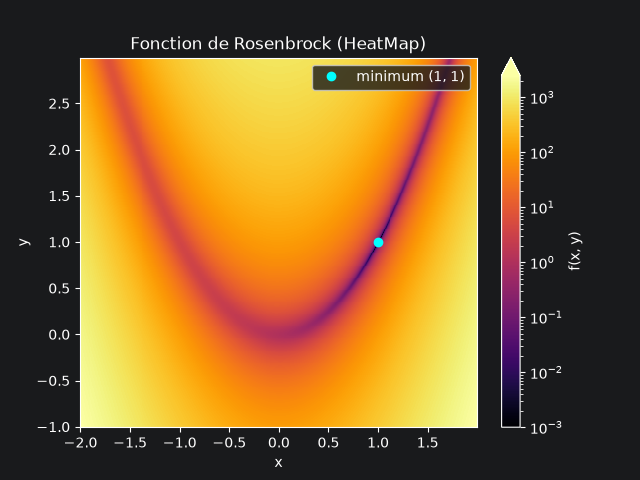

In [7]:
fig, ax = plt.subplots()

norm = LogNorm(vmin=1e-3, vmax=Z.max())
pcm = ax.pcolormesh(X, Y, Z, norm=norm, cmap="inferno", shading="auto")
fig.colorbar(pcm, ax=ax, extend="max", label="f(x, y)")

ax.plot(1, 1, ".", c="cyan", ms=12, label="minimum (1, 1)")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Fonction de Rosenbrock (HeatMap)")
ax.legend(loc="upper right")

plt.show()

In [10]:
import math
from utils.point import Point

def _f(p: Point)->float:
    return f(p[0], p[1])

def gradient_pas_fixe_historique(fonction, x0: Point, alpha: float, epsilon: float, nbitr: int, pas_historique: int = 1):
    x = x0
    h = 1e-5
    historique = [x]

    for k in range(1, nbitr + 1):
        # Approximation du gradient (différences finies centrées)
        grad_values = []
        for j in range(x.dimension):
            val_plus = list(x.values)
            val_moins = list(x.values)
            val_plus[j] += h
            val_moins[j] -= h
            grad_values.append((fonction(Point(val_plus)) - fonction(Point(val_moins))) / (2 * h))

        grad = Point(grad_values)

        # Critère d'arrêt
        if math.sqrt(sum(g ** 2 for g in grad.values)) < epsilon:
            break

        x = x - grad.multiply_with_scalar(alpha)

        if k % pas_historique == 0:
            historique.append(x)

    if historique[-1] is not x:
        historique.append(x)

    return x, historique

##### Recherche du minimum

In [11]:
x_init = Point([0, 0])
alpha = 0.0001
epsilon = 1e-6
nbitr = 200000

x_final, historique = gradient_pas_fixe_historique(_f, x_init, alpha, epsilon, nbitr, pas_historique=100)

print("Point final :", x_final)
print("f =", _f(x_final))
print("Points enregistrés :", len(historique))

Point final : Point([0.9998975713349993, 0.9997947433380548], Dimension: 2)
f = 1.0508426950103087e-08
Points enregistrés : 2001


##### Trajectoire

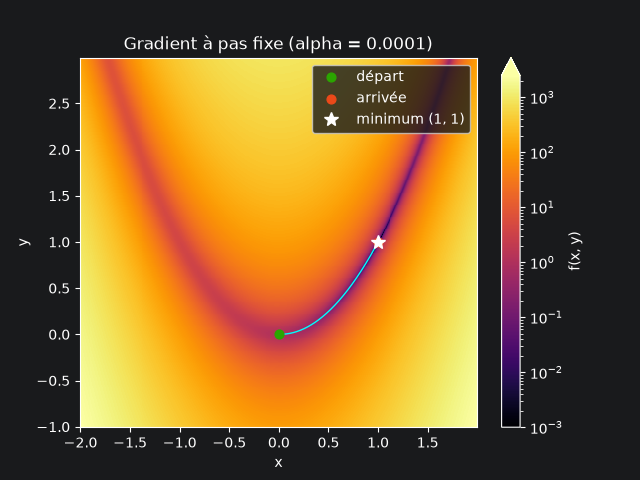

In [12]:
fig, ax = plt.subplots()

pcm = ax.pcolormesh(X, Y, Z, norm=norm, cmap="inferno", shading="auto")
fig.colorbar(pcm, ax=ax, extend="max", label="f(x, y)")

xs = [p[0] for p in historique]
ys = [p[1] for p in historique]

ax.plot(xs, ys, "-", c="cyan", lw=1, zorder=2)
ax.scatter(xs[0], ys[0], c="#2ba500", s=40, zorder=3, label="départ")
ax.scatter(xs[-1], ys[-1], c="#eb4919", s=40, zorder=3, label="arrivée")
ax.plot(1, 1, ".", c="white", ms=10, zorder=3, label="minimum (1, 1)")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Gradient à pas fixe (alpha = " + str(alpha) + ")")
ax.legend(loc="upper right")

plt.show()

##### Animation

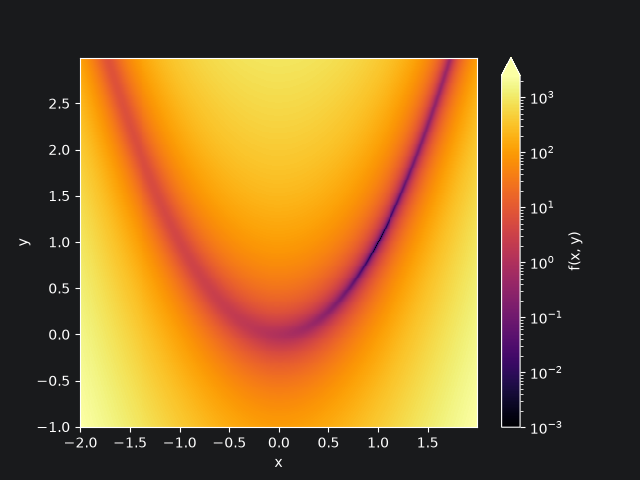

In [17]:
from matplotlib.animation import FuncAnimation
from utils.control import Control

fig, ax = plt.subplots()

pcm = ax.pcolormesh(X, Y, Z, norm=norm, cmap="inferno", shading="auto")
fig.colorbar(pcm, ax=ax, extend="max", label="f(x, y)")

ax.set_xlabel("x")
ax.set_ylabel("y")

trace_plot, = ax.plot([], [], "-", c="cyan", lw=1, zorder=2)
current_plot, = ax.plot([], [], "o", c="#eb4919", zorder=3)

def update(frame):
    ax.set_title("Itération : " + str(frame * 100))

    trace_plot.set_data(xs[:frame + 1], ys[:frame + 1])
    current_plot.set_data([xs[frame]], [ys[frame]])

    return trace_plot, current_plot

# On saute des frames pour garder une animation fluide
frames = list(range(0, len(historique), max(1, len(historique) // 200)))
if frames[-1] != len(historique) - 1:
    frames.append(len(historique) - 1)

anim = FuncAnimation(fig, update, frames=frames, interval=50, repeat=False)
control = Control(fig, anim, update, len(historique))

plt.show()

##### Convergence de f

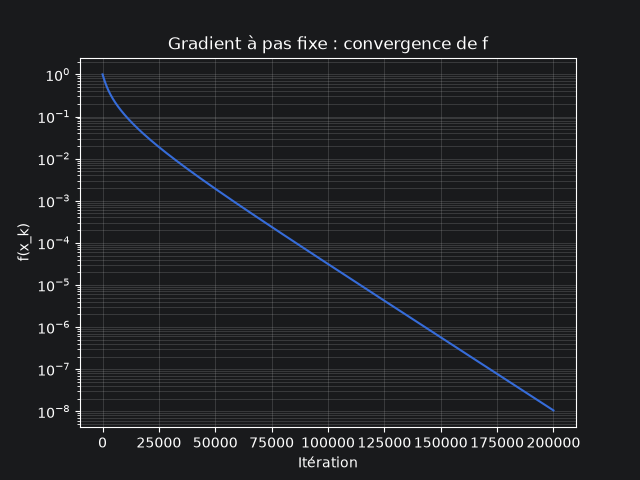

In [14]:
valeurs = [_f(p) for p in historique]
iterations = [i * 100 for i in range(len(historique))]
iterations[-1] = min(iterations[-1], nbitr)

fig, ax = plt.subplots()

ax.semilogy(iterations, valeurs)
ax.set_xlabel("Itération")
ax.set_ylabel("f(x_k)")
ax.set_title("Gradient à pas fixe : convergence de f")
ax.grid(True, which="both", alpha=0.3)

plt.show()

##### Distance au minimum (1, 1)

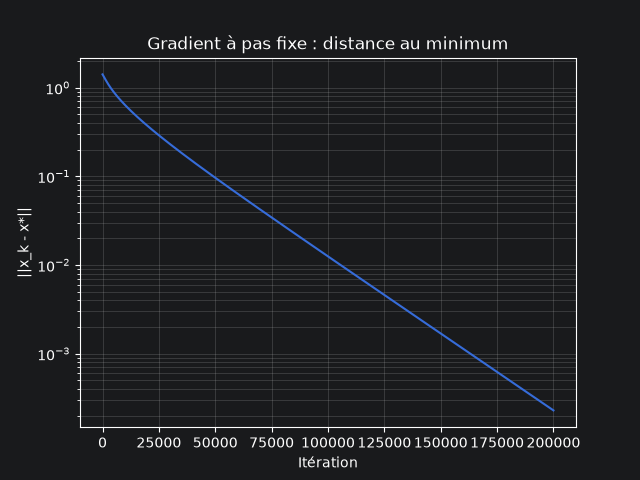

In [15]:
distances = [math.hypot(p[0] - 1, p[1] - 1) for p in historique]

fig, ax = plt.subplots()

ax.semilogy(iterations, distances)
ax.set_xlabel("Itération")
ax.set_ylabel("||x_k - x*||")
ax.set_title("Gradient à pas fixe : distance au minimum")
ax.grid(True, which="both", alpha=0.3)

plt.show()

##### Influence du pas alpha

Un pas trop grand fait diverger la méthode, un pas trop petit la rend très lente. Sur Rosenbrock la limite de stabilité près du minimum est d'environ 0.002.

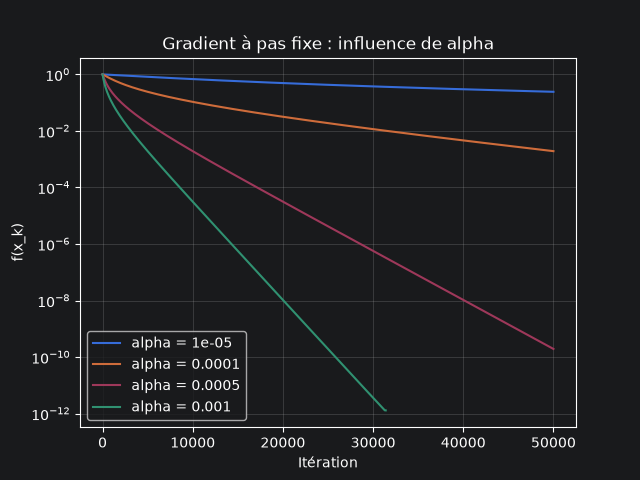

In [16]:
alphas = [0.00001, 0.0001, 0.0005, 0.001]

fig, ax = plt.subplots()

for a in alphas:
    _, h = gradient_pas_fixe_historique(_f, Point([0, 0]), a, epsilon, 50000, pas_historique=100)
    vals = [_f(p) for p in h]
    ax.semilogy([i * 100 for i in range(len(vals))], vals, label="alpha = " + str(a))

ax.set_xlabel("Itération")
ax.set_ylabel("f(x_k)")
ax.set_title("Gradient à pas fixe : influence de alpha")
ax.grid(True, which="both", alpha=0.3)
ax.legend()

plt.show()